# ***E-Commerce Sales & Customer Analytics***

In [1]:
project_name = "E-Commerce Sales & Customer Analytics"
print(project_name)

E-Commerce Sales & Customer Analytics


In [2]:
%pip install pandas numpy matplotlib seaborn

Note: you may need to restart the kernel to use updated packages.


In [4]:
# Import the packages
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [6]:
# sns.set_style("whitegrid")

In [16]:
# Load the data
orders = pd.read_csv("olist_orders_dataset.csv")
# print(orders)
orders_items = pd.read_csv("olist_order_items_dataset.csv")
# print(orders_items)
customers = pd.read_csv("olist_customers_dataset.csv")
# print(customers)
payments = pd.read_csv("olist_order_payments_dataset.csv")
# print(payments)
reviews = pd.read_csv("olist_order_reviews_dataset.csv")
# print(reviews)

In [17]:
# first five rows
print(orders.head())

                           order_id                       customer_id  \
0  e481f51cbdc54678b7cc49136f2d6af7  9ef432eb6251297304e76186b10a928d   
1  53cdb2fc8bc7dce0b6741e2150273451  b0830fb4747a6c6d20dea0b8c802d7ef   
2  47770eb9100c2d0c44946d9cf07ec65d  41ce2a54c0b03bf3443c3d931a367089   
3  949d5b44dbf5de918fe9c16f97b45f8a  f88197465ea7920adcdbec7375364d82   
4  ad21c59c0840e6cb83a9ceb5573f8159  8ab97904e6daea8866dbdbc4fb7aad2c   

  order_status order_purchase_timestamp    order_approved_at  \
0    delivered      2017-10-02 10:56:33  2017-10-02 11:07:15   
1    delivered      2018-07-24 20:41:37  2018-07-26 03:24:27   
2    delivered      2018-08-08 08:38:49  2018-08-08 08:55:23   
3    delivered      2017-11-18 19:28:06  2017-11-18 19:45:59   
4    delivered      2018-02-13 21:18:39  2018-02-13 22:20:29   

  order_delivered_carrier_date order_delivered_customer_date  \
0          2017-10-04 19:55:00           2017-10-10 21:25:13   
1          2018-07-26 14:31:00           2018-08

In [18]:
# shape
print(orders.shape)

(99441, 8)


In [19]:
# check data types
print(orders.info())

<class 'pandas.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype
---  ------                         --------------  -----
 0   order_id                       99441 non-null  str  
 1   customer_id                    99441 non-null  str  
 2   order_status                   99441 non-null  str  
 3   order_purchase_timestamp       99441 non-null  str  
 4   order_approved_at              99281 non-null  str  
 5   order_delivered_carrier_date   97658 non-null  str  
 6   order_delivered_customer_date  96476 non-null  str  
 7   order_estimated_delivery_date  99441 non-null  str  
dtypes: str(8)
memory usage: 21.9 MB
None


In [21]:
# missing values
print(orders.isnull().sum())

order_id                            0
customer_id                         0
order_status                        0
order_purchase_timestamp            0
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
order_estimated_delivery_date       0
dtype: int64


In [23]:
# duplicate values
print(orders.duplicated().sum())

0


### ***Data Cleaning***

In [26]:
# shape of all datasets
print(f"Orders :- {orders.shape}")
print(f"Order Items :- {orders_items.shape}")
print(f"Customers :- {customers.shape}")
print(f"Payments :- {payments.shape}")
print(f"Reviews :- {reviews.shape}")

Orders :- (99441, 8)
Order Items :- (112650, 7)
Customers :- (99441, 5)
Payments :- (103886, 5)
Reviews :- (99224, 7)


In [31]:
# columns names
print("Orders Columns:- ")
print(orders.columns)

print("\nOrder Items Columns:- ")
print(orders_items.columns)

print("\nCustomers Columns:- ")
print(customers.columns)

print("\nPayments Columns:-")
print(payments.columns)

print("\nReviews Columns:-")
print(reviews.columns)

Orders Columns:- 
Index(['order_id', 'customer_id', 'order_status', 'order_purchase_timestamp',
       'order_approved_at', 'order_delivered_carrier_date',
       'order_delivered_customer_date', 'order_estimated_delivery_date'],
      dtype='str')

Order Items Columns:- 
Index(['order_id', 'order_item_id', 'product_id', 'seller_id',
       'shipping_limit_date', 'price', 'freight_value'],
      dtype='str')

Customers Columns:- 
Index(['customer_id', 'customer_unique_id', 'customer_zip_code_prefix',
       'customer_city', 'customer_state'],
      dtype='str')

Payments Columns:-
Index(['order_id', 'payment_sequential', 'payment_type',
       'payment_installments', 'payment_value'],
      dtype='str')

Reviews Columns:-
Index(['review_id', 'order_id', 'review_score', 'review_comment_title',
       'review_comment_message', 'review_creation_date',
       'review_answer_timestamp'],
      dtype='str')


In [41]:
# missing values in all datasets
print("Orders Missing Values:")
print(orders.isnull().sum())

print("\nOrder Items Missing Values:")
print(orders_items.isnull().sum())

print("\nCustomers Missing Values:")
print(customers.isnull().sum())

print("\nPayments Missing Values:")
print(payments.isnull().sum())

print("\nReviews Missing Values:")
print(reviews.isnull().sum())

Orders Missing Values:
order_id                            0
customer_id                         0
order_status                        0
order_purchase_timestamp            0
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
order_estimated_delivery_date       0
dtype: int64

Order Items Missing Values:
order_id               0
order_item_id          0
product_id             0
seller_id              0
shipping_limit_date    0
price                  0
freight_value          0
dtype: int64

Customers Missing Values:
customer_id                 0
customer_unique_id          0
customer_zip_code_prefix    0
customer_city               0
customer_state              0
dtype: int64

Payments Missing Values:
order_id                0
payment_sequential      0
payment_type            0
payment_installments    0
payment_value           0
dtype: int64

Reviews Missing Values:
review_id                      0
order_id                  

In [43]:
# duplicate Values
print(f"Orders Duplicate Values :- {orders.duplicated().sum()}")
print(f"Order Items Duplicate Values :- {orders_items.duplicated().sum()}")
print(f"Customers Duplicate Values :- {customers.duplicated().sum()}")
print(f"Payments Duplicate Values :- {payments.duplicated().sum()}")
print(f"Reviews Dulplicate Values :- {reviews.duplicated().sum()}")

Orders Duplicate Values :- 0
Order Items Duplicate Values :- 0
Customers Duplicate Values :- 0
Payments Duplicate Values :- 0
Reviews Dulplicate Values :- 0


In [44]:
# Convert date columns into datetime format
orders["order_purchase_timestamp"] = pd.to_datetime(
    orders["order_purchase_timestamp"],
    errors="coerce")

orders["order_approved_at"] = pd.to_datetime(
    orders["order_approved_at"],
    errors="coerce")

orders["order_delivered_customer_date"] = pd.to_datetime(
    orders["order_delivered_customer_date"],
    errors="coerce")

orders["order_estimated_delivery_date"] = pd.to_datetime(
    orders["order_estimated_delivery_date"],
    errors="coerce")

In [45]:
orders.info()

<class 'pandas.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype         
---  ------                         --------------  -----         
 0   order_id                       99441 non-null  str           
 1   customer_id                    99441 non-null  str           
 2   order_status                   99441 non-null  str           
 3   order_purchase_timestamp       99441 non-null  datetime64[us]
 4   order_approved_at              99281 non-null  datetime64[us]
 5   order_delivered_carrier_date   97658 non-null  str           
 6   order_delivered_customer_date  96476 non-null  datetime64[us]
 7   order_estimated_delivery_date  99441 non-null  datetime64[us]
dtypes: datetime64[us](4), str(4)
memory usage: 14.8 MB


In [48]:
# data types of order items
orders_items[["price", "freight_value"]].dtypes

price            float64
freight_value    float64
dtype: object

In [56]:
# Convert columns to numeric format
orders_items["price"] = pd.to_numeric(orders_items["price"],errors="coerce")

orders_items["freight_value"] = pd.to_numeric(orders_items["freight_value"],errors="coerce")

In [58]:
# Basic statistical infomation
print(orders_items[["price","freight_value"]].describe())

               price  freight_value
count  112650.000000  112650.000000
mean      120.653739      19.990320
std       183.633928      15.806405
min         0.850000       0.000000
25%        39.900000      13.080000
50%        74.990000      16.260000
75%       134.900000      21.150000
max      6735.000000     409.680000


In [59]:
# merge orders and orders items
sales_data = pd.merge(orders,orders_items,on="order_id",how="inner")

In [60]:
print(sales_data.head())

                           order_id                       customer_id  \
0  e481f51cbdc54678b7cc49136f2d6af7  9ef432eb6251297304e76186b10a928d   
1  53cdb2fc8bc7dce0b6741e2150273451  b0830fb4747a6c6d20dea0b8c802d7ef   
2  47770eb9100c2d0c44946d9cf07ec65d  41ce2a54c0b03bf3443c3d931a367089   
3  949d5b44dbf5de918fe9c16f97b45f8a  f88197465ea7920adcdbec7375364d82   
4  ad21c59c0840e6cb83a9ceb5573f8159  8ab97904e6daea8866dbdbc4fb7aad2c   

  order_status order_purchase_timestamp   order_approved_at  \
0    delivered      2017-10-02 10:56:33 2017-10-02 11:07:15   
1    delivered      2018-07-24 20:41:37 2018-07-26 03:24:27   
2    delivered      2018-08-08 08:38:49 2018-08-08 08:55:23   
3    delivered      2017-11-18 19:28:06 2017-11-18 19:45:59   
4    delivered      2018-02-13 21:18:39 2018-02-13 22:20:29   

  order_delivered_carrier_date order_delivered_customer_date  \
0          2017-10-04 19:55:00           2017-10-10 21:25:13   
1          2018-07-26 14:31:00           2018-08-07 15

In [61]:
print(sales_data.shape)

(112650, 14)


## ***Revenue Analysis***

In [62]:
# calculate total product revenue
total_revenue = sales_data["price"].sum()
print(total_revenue)

13591643.700000001


In [63]:
# calculate unique orders
total_orders = sales_data["order_id"].nunique()
print(total_orders)

98666


In [64]:
# Average order values
avg_order_value = total_revenue / total_orders
print(avg_order_value)

137.75407637889447


In [65]:
# total items sold
total_items_sold = sales_data["order_item_id"].count()
print(total_items_sold)

112650


## ***Monthly Sales Analysis***

In [69]:
# extract year and month from order purchase timestamp
sales_data["year"] = sales_data["order_purchase_timestamp"].dt.year
print(sales_data["year"])

sales_data["month"] = sales_data["order_purchase_timestamp"].dt.year
print(sales_data["month"])

0         2017
1         2018
2         2018
3         2017
4         2018
          ... 
112645    2018
112646    2017
112647    2018
112648    2018
112649    2018
Name: year, Length: 112650, dtype: int32
0         2017
1         2018
2         2018
3         2017
4         2018
          ... 
112645    2018
112646    2017
112647    2018
112648    2018
112649    2018
Name: month, Length: 112650, dtype: int32


In [74]:
# Monthly Revenue
monthly_sales = sales_data.groupby(["year","month"])["price"].sum().reset_index()
print(monthly_sales.head())

   year  month       price
0  2016   2016    49785.92
1  2017   2017  6155806.98
2  2018   2018  7386050.80


In [76]:
# create a year-month column
monthly_sales["year-month"] = (monthly_sales["year"].astype(str) + "-" + monthly_sales["month"].astype(str).str.zfill(2))
print(monthly_sales.head())

   year  month       price year-month
0  2016   2016    49785.92  2016-2016
1  2017   2017  6155806.98  2017-2017
2  2018   2018  7386050.80  2018-2018


In [78]:
# Sort monthly sales in descending order
monthly_sales_sorted = monthly_sales.sort_values(by="price",ascending=False)
print(monthly_sales_sorted.head(10))

   year  month       price year-month
2  2018   2018  7386050.80  2018-2018
1  2017   2017  6155806.98  2017-2017
0  2016   2016    49785.92  2016-2016


# ***Product Category Analysis***

In [80]:
# Load products dataset
products = pd.read_csv("olist_products_dataset.csv")
print(products.head())

                         product_id  product_category_name  \
0  1e9e8ef04dbcff4541ed26657ea517e5             perfumaria   
1  3aa071139cb16b67ca9e5dea641aaa2f                  artes   
2  96bd76ec8810374ed1b65e291975717f          esporte_lazer   
3  cef67bcfe19066a932b7673e239eb23d                  bebes   
4  9dc1a7de274444849c219cff195d0b71  utilidades_domesticas   

   product_name_lenght  product_description_lenght  product_photos_qty  \
0                 40.0                       287.0                 1.0   
1                 44.0                       276.0                 1.0   
2                 46.0                       250.0                 1.0   
3                 27.0                       261.0                 1.0   
4                 37.0                       402.0                 4.0   

   product_weight_g  product_length_cm  product_height_cm  product_width_cm  
0             225.0               16.0               10.0              14.0  
1            1000.0       

In [81]:
# Merge product information with sales data
sales_data = pd.merge(sales_data,products[["product_id","product_category_name"]],on="product_id",how="left")
print(sales_data.head())

                           order_id                       customer_id  \
0  e481f51cbdc54678b7cc49136f2d6af7  9ef432eb6251297304e76186b10a928d   
1  53cdb2fc8bc7dce0b6741e2150273451  b0830fb4747a6c6d20dea0b8c802d7ef   
2  47770eb9100c2d0c44946d9cf07ec65d  41ce2a54c0b03bf3443c3d931a367089   
3  949d5b44dbf5de918fe9c16f97b45f8a  f88197465ea7920adcdbec7375364d82   
4  ad21c59c0840e6cb83a9ceb5573f8159  8ab97904e6daea8866dbdbc4fb7aad2c   

  order_status order_purchase_timestamp   order_approved_at  \
0    delivered      2017-10-02 10:56:33 2017-10-02 11:07:15   
1    delivered      2018-07-24 20:41:37 2018-07-26 03:24:27   
2    delivered      2018-08-08 08:38:49 2018-08-08 08:55:23   
3    delivered      2017-11-18 19:28:06 2017-11-18 19:45:59   
4    delivered      2018-02-13 21:18:39 2018-02-13 22:20:29   

  order_delivered_carrier_date order_delivered_customer_date  \
0          2017-10-04 19:55:00           2017-10-10 21:25:13   
1          2018-07-26 14:31:00           2018-08-07 15

In [82]:
# Calculate revenue by product category
category_sales = sales_data.groupby("product_category_name")["price"].sum().reset_index()

category_sales = category_sales.sort_values(by="price",ascending=False)
print(category_sales.head(10))

     product_category_name       price
11            beleza_saude  1258681.34
66      relogios_presentes  1205005.68
13         cama_mesa_banho  1036988.68
32           esporte_lazer   988048.97
44  informatica_acessorios   911954.32
54        moveis_decoracao   729762.49
26              cool_stuff   635290.85
72   utilidades_domesticas   632248.66
8               automotivo   592720.11
40      ferramentas_jardim   485256.46


In [83]:
# top 10 product categories
top_categories = category_sales.head(10)
print(top_categories)

     product_category_name       price
11            beleza_saude  1258681.34
66      relogios_presentes  1205005.68
13         cama_mesa_banho  1036988.68
32           esporte_lazer   988048.97
44  informatica_acessorios   911954.32
54        moveis_decoracao   729762.49
26              cool_stuff   635290.85
72   utilidades_domesticas   632248.66
8               automotivo   592720.11
40      ferramentas_jardim   485256.46


## ***Customer Analysis***

In [84]:
# Merge customer information
sales_data = pd.merge(sales_data,customers[["customer_id", "customer_unique_id", "customer_city", "customer_state"]],on="customer_id",how="left")
print(sales_data.head())

                           order_id                       customer_id  \
0  e481f51cbdc54678b7cc49136f2d6af7  9ef432eb6251297304e76186b10a928d   
1  53cdb2fc8bc7dce0b6741e2150273451  b0830fb4747a6c6d20dea0b8c802d7ef   
2  47770eb9100c2d0c44946d9cf07ec65d  41ce2a54c0b03bf3443c3d931a367089   
3  949d5b44dbf5de918fe9c16f97b45f8a  f88197465ea7920adcdbec7375364d82   
4  ad21c59c0840e6cb83a9ceb5573f8159  8ab97904e6daea8866dbdbc4fb7aad2c   

  order_status order_purchase_timestamp   order_approved_at  \
0    delivered      2017-10-02 10:56:33 2017-10-02 11:07:15   
1    delivered      2018-07-24 20:41:37 2018-07-26 03:24:27   
2    delivered      2018-08-08 08:38:49 2018-08-08 08:55:23   
3    delivered      2017-11-18 19:28:06 2017-11-18 19:45:59   
4    delivered      2018-02-13 21:18:39 2018-02-13 22:20:29   

  order_delivered_carrier_date order_delivered_customer_date  \
0          2017-10-04 19:55:00           2017-10-10 21:25:13   
1          2018-07-26 14:31:00           2018-08-07 15

In [85]:
# Count unique customers
total_customers = sales_data["customer_unique_id"].nunique()
print("Total Unique Customers:", total_customers)

Total Unique Customers: 95420


In [86]:
# Calculate revenue by customer state
state_sales = sales_data.groupby("customer_state")["price"].sum().reset_index()
state_sales = state_sales.sort_values(by="price",ascending=False)
print(state_sales.head(10))

   customer_state       price
25             SP  5202955.05
18             RJ  1824092.67
10             MG  1585308.03
22             RS   750304.02
17             PR   683083.76
23             SC   520553.34
4              BA   511349.99
6              DF   302603.94
8              GO   294591.95
7              ES   275037.31


In [87]:
# Calculate revenue by customer city
city_sales = sales_data.groupby("customer_city")["price"].sum().reset_index()
city_sales = city_sales.sort_values(by="price",ascending=False)
print(city_sales.head(10))

       customer_city       price
3588       sao paulo  1914924.54
3147  rio de janeiro   992538.86
452   belo horizonte   355611.13
557         brasilia   301920.25
1141        curitiba   211738.06
2956    porto alegre   190562.08
705         campinas   187844.53
3239        salvador   181104.42
1526       guarulhos   144268.39
2455         niteroi   117907.12


## ***Order Status Analysis***

In [88]:
# Count orders by status
order_status = orders["order_status"].value_counts()
print(order_status)

order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64


In [89]:
# Calculate order status percentage
order_status_percentage = (orders["order_status"].value_counts(normalize=True) * 100)
print(order_status_percentage)

order_status
delivered      97.020344
shipped         1.113223
canceled        0.628513
unavailable     0.612423
invoiced        0.315765
processing      0.302692
created         0.005028
approved        0.002011
Name: proportion, dtype: float64


## ***Delivery Performance Analysis***

In [91]:
# Calculate actual delivery time in days
orders["delivery_days"] = (orders["order_delivered_customer_date"] - orders["order_purchase_timestamp"]).dt.total_seconds() / 86400
print(orders["delivery_days"].head())

0     8.436574
1    13.782037
2     9.394213
3    13.208750
4     2.873877
Name: delivery_days, dtype: float64


In [92]:
# Calculate delivery statistics
delivery_summary = orders["delivery_days"].describe()
print(delivery_summary)

count    96476.000000
mean        12.558702
std          9.546530
min          0.533414
25%          6.766403
50%         10.217755
75%         15.720327
max        209.628611
Name: delivery_days, dtype: float64


In [94]:
# Identify orders delivered after the estimated date
orders["late_delivery"] = (orders["order_delivered_customer_date"] > orders["order_estimated_delivery_date"])

print(orders[["order_id","order_delivered_customer_date","order_estimated_delivery_date","late_delivery"]].head(10))

                           order_id order_delivered_customer_date  \
0  e481f51cbdc54678b7cc49136f2d6af7           2017-10-10 21:25:13   
1  53cdb2fc8bc7dce0b6741e2150273451           2018-08-07 15:27:45   
2  47770eb9100c2d0c44946d9cf07ec65d           2018-08-17 18:06:29   
3  949d5b44dbf5de918fe9c16f97b45f8a           2017-12-02 00:28:42   
4  ad21c59c0840e6cb83a9ceb5573f8159           2018-02-16 18:17:02   
5  a4591c265e18cb1dcee52889e2d8acc3           2017-07-26 10:57:55   
6  136cce7faa42fdb2cefd53fdc79a6098                           NaT   
7  6514b8ad8028c9f2cc2374ded245783f           2017-05-26 12:55:51   
8  76c6e866289321a7c93b82b54852dc33           2017-02-02 14:08:10   
9  e69bfb5eb88e0ed6a785585b27e16dbf           2017-08-16 17:14:30   

  order_estimated_delivery_date  late_delivery  
0                    2017-10-18          False  
1                    2018-08-13          False  
2                    2018-09-04          False  
3                    2017-12-15          Fal

In [97]:
# Calculate late delivery percentage among delivered orders
delivered_orders = orders[orders["order_delivered_customer_date"].notna() & orders["order_estimated_delivery_date"].notna()]
late_percentage = (delivered_orders["late_delivery"].mean() * 100)
print("Late Delivery Percentage:",round(late_percentage,2),"%")

Late Delivery Percentage: 8.11 %


## ***Data Visualization***

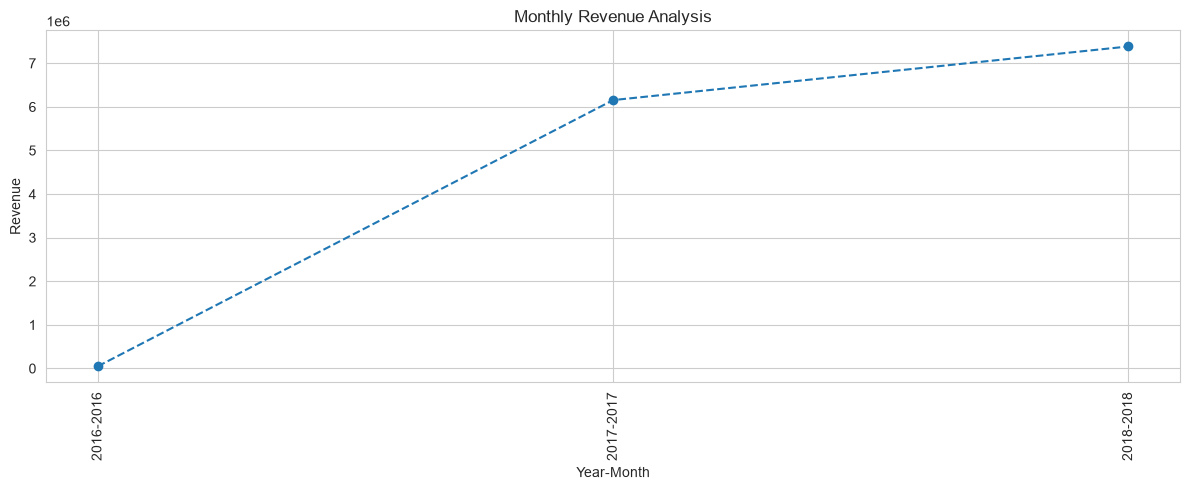

In [99]:
# Import matplotlib
import matplotlib.pyplot as plt

# monthly revenue
plt.figure(figsize=(12,5))
plt.plot(monthly_sales["year-month"],monthly_sales["price"],marker="o",linestyle="dashed")
plt.title("Monthly Revenue Analysis")
plt.xlabel("Year-Month")
plt.ylabel("Revenue")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

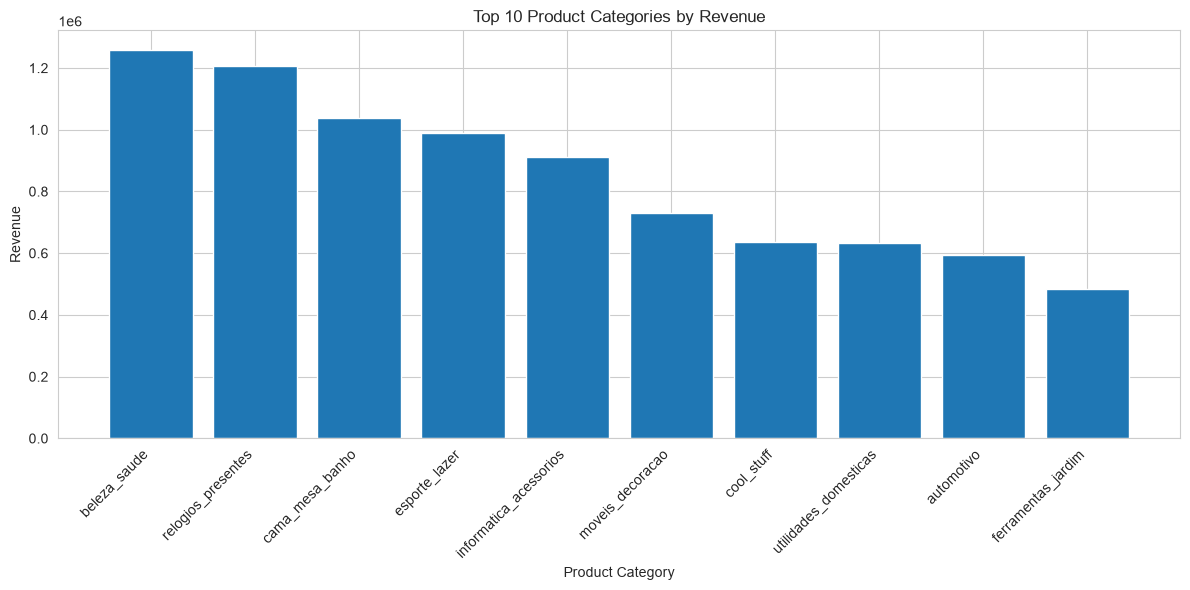

In [100]:
# top 10 product categories
plt.figure(figsize=(12,6))
plt.bar(top_categories["product_category_name"],top_categories["price"])
plt.title("Top 10 Product Categories by Revenue")
plt.xlabel("Product Category")
plt.ylabel("Revenue")
plt.xticks(rotation=45,ha="right")
plt.tight_layout()
plt.show()

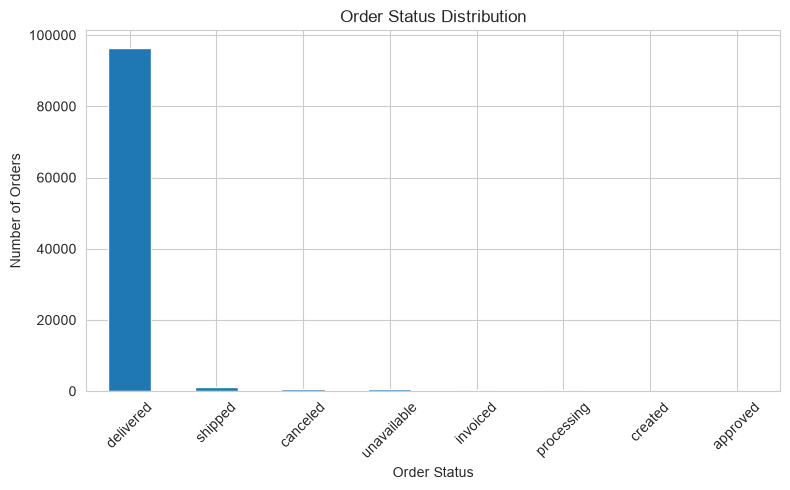

In [101]:
# order status distribution
plt.figure(figsize=(8,5))
order_status.plot(kind="bar")
plt.title("Order Status Distribution")
plt.xlabel("Order Status")
plt.ylabel("Number of Orders")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

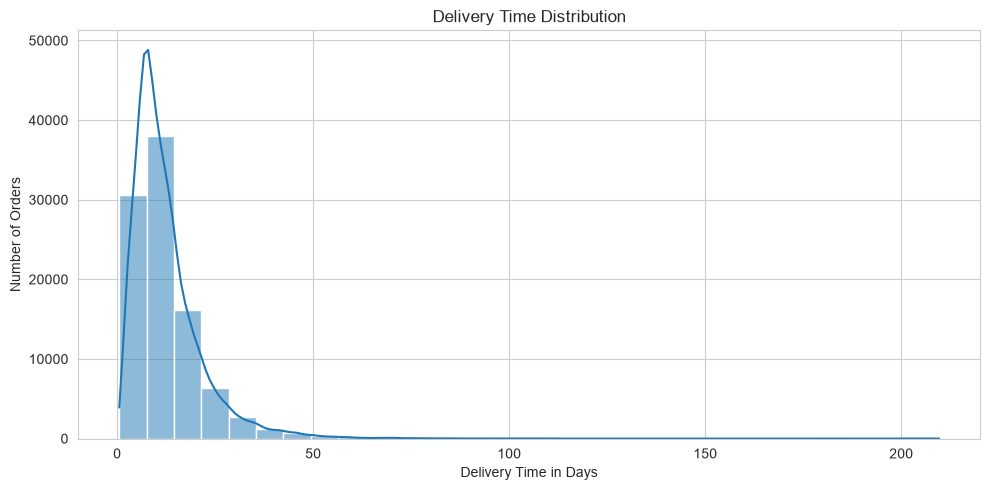

In [102]:
# delivery time distribution
import seaborn as sns
plt.figure(figsize=(10,5))
sns.histplot(data=orders,x="delivery_days",bins=30,kde=True)
plt.title("Delivery Time Distribution")
plt.xlabel("Delivery Time in Days")
plt.ylabel("Number of Orders")
plt.tight_layout()
plt.show()

## ***Payment Analysis***

In [103]:
# orders by payment method
payment_methods = payments["payment_type"].value_counts()
print(payment_methods)

payment_type
credit_card    76795
boleto         19784
voucher         5775
debit_card      1529
not_defined        3
Name: count, dtype: int64


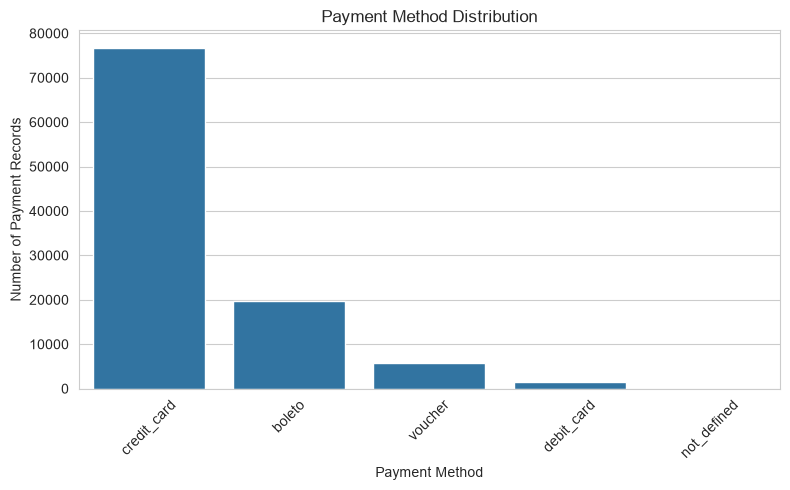

In [104]:
# Visualize payment methods
plt.figure(figsize=(8,5))
sns.countplot(data=payments,x="payment_type",order=payments["payment_type"].value_counts().index)
plt.title("Payment Method Distribution")
plt.xlabel("Payment Method")
plt.ylabel("Number of Payment Records")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [105]:
# Calculate total payment value by payment method
payment_analysis = payments.groupby("payment_type")["payment_value"].sum().reset_index()
payment_analysis = payment_analysis.sort_values(by="payment_value",ascending=False)
print(payment_analysis)

  payment_type  payment_value
1  credit_card    12542084.19
0       boleto     2869361.27
4      voucher      379436.87
2   debit_card      217989.79
3  not_defined           0.00


## ***Customer Review Analysis***

In [106]:
# Count each review score
review_scores = reviews["review_score"].value_counts().sort_index()
print(review_scores)

review_score
1    11424
2     3151
3     8179
4    19142
5    57328
Name: count, dtype: int64


In [107]:
# Calculate average review score
average_review = reviews["review_score"].mean()
print("Average Review Score:",round(average_review,2))

Average Review Score: 4.09


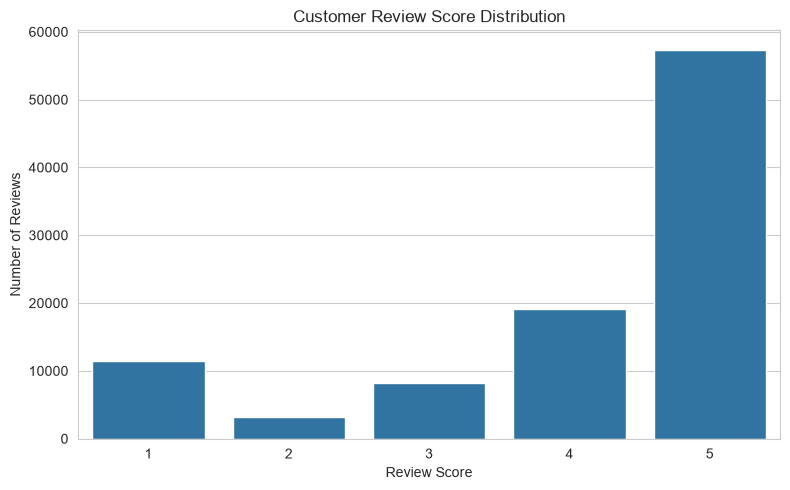

In [108]:
# Visualize review score distribution
plt.figure(figsize=(8,5))
sns.countplot(data=reviews,x="review_score",order=[1,2,3,4,5])
plt.title("Customer Review Score Distribution")
plt.xlabel("Review Score")
plt.ylabel("Number of Reviews")
plt.tight_layout()
plt.show()

In [110]:
# Calculate positive, neutral and negative review percentages
positive_reviews = (reviews["review_score"] >= 4).sum()
neutral_reviews = (reviews["review_score"] == 3).sum()
negative_reviews = (reviews["review_score"] <= 2).sum()
total_reviews = reviews["review_score"].notna().sum()
print("Positive Reviews:",round(positive_reviews / total_reviews * 100,2),"%")
print("Neutral Reviews:",round(neutral_reviews / total_reviews * 100,2),"%")
print("Negative Reviews:",round(negative_reviews / total_reviews * 100,2),"%")

Positive Reviews: 77.07 %
Neutral Reviews: 8.24 %
Negative Reviews: 14.69 %


## ***Repeat Customer Analysis***

In [122]:
# Select delivered orders
delivered_orders = orders[orders["order_status"] == "delivered"].copy()
# Merge customer information
customer_orders = pd.merge(delivered_orders[["order_id","customer_id","order_purchase_timestamp"]],customers[["customer_id","customer_unique_id"]],on="customer_id",how="left")
print(customer_orders.head())

                           order_id                       customer_id  \
0  e481f51cbdc54678b7cc49136f2d6af7  9ef432eb6251297304e76186b10a928d   
1  53cdb2fc8bc7dce0b6741e2150273451  b0830fb4747a6c6d20dea0b8c802d7ef   
2  47770eb9100c2d0c44946d9cf07ec65d  41ce2a54c0b03bf3443c3d931a367089   
3  949d5b44dbf5de918fe9c16f97b45f8a  f88197465ea7920adcdbec7375364d82   
4  ad21c59c0840e6cb83a9ceb5573f8159  8ab97904e6daea8866dbdbc4fb7aad2c   

  order_purchase_timestamp                customer_unique_id  
0      2017-10-02 10:56:33  7c396fd4830fd04220f754e42b4e5bff  
1      2018-07-24 20:41:37  af07308b275d755c9edb36a90c618231  
2      2018-08-08 08:38:49  3a653a41f6f9fc3d2a113cf8398680e8  
3      2017-11-18 19:28:06  7c142cf63193a1473d2e66489a9ae977  
4      2018-02-13 21:18:39  72632f0f9dd73dfee390c9b22eb56dd6  


In [114]:
customers.keys()

Index(['customer_id', 'customer_unique_id', 'customer_zip_code_prefix',
       'customer_city', 'customer_state'],
      dtype='str')

In [123]:
# Count delivered orders for each unique customer
customer_order_counts = customer_orders.groupby("customer_unique_id")["order_id"].nunique().reset_index()
customer_order_counts.columns = ["customer_unique_id","total_orders"]
print(customer_order_counts.head())

                 customer_unique_id  total_orders
0  0000366f3b9a7992bf8c76cfdf3221e2             1
1  0000b849f77a49e4a4ce2b2a4ca5be3f             1
2  0000f46a3911fa3c0805444483337064             1
3  0000f6ccb0745a6a4b88665a16c9f078             1
4  0004aac84e0df4da2b147fca70cf8255             1


In [124]:
# Filter customers with more than one delivered order
repeat_customers = customer_order_counts[customer_order_counts["total_orders"] > 1].copy()
print(repeat_customers.head())

                   customer_unique_id  total_orders
104  004288347e5e88a27ded2bb23747066c             2
243  00a39521eb40f7012db50455bf083460             2
305  00cc12a6d8b578b8ebd21ea4e2ae8b27             2
404  011575986092c30523ecb71ff10cb473             2
419  011b4adcd54683b480c4d841250a987f             2


In [125]:
# Calculate repeat customer percentage
total_unique_customers = customer_order_counts["customer_unique_id"].nunique()
total_repeat_customers = repeat_customers["customer_unique_id"].nunique()
repeat_customer_percentage = (total_repeat_customers / total_unique_customers * 100)
print("Total Customers:", total_unique_customers)
print("Repeat Customers:", total_repeat_customers)
print("Repeat Customer Percentage:",round(repeat_customer_percentage,2),"%")

Total Customers: 93358
Repeat Customers: 2801
Repeat Customer Percentage: 3.0 %


## ***Advance Visualization --- State-wise Revenue***

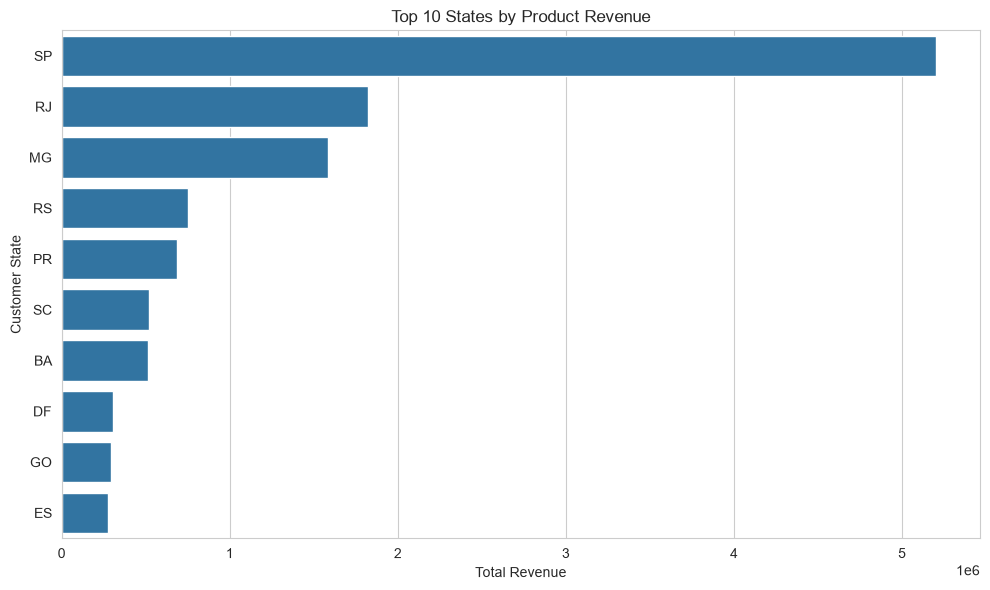

In [126]:
# top 10 states by revenue
top_states = state_sales.head(10)
plt.figure(figsize=(10,6))
sns.barplot(data=top_states,x="price",y="customer_state")
plt.title("Top 10 States by Product Revenue")
plt.xlabel("Total Revenue")
plt.ylabel("Customer State")
plt.tight_layout()
plt.show()

In [127]:
# required delivery columns
delivery_info = orders[["order_id","delivery_days","late_delivery"]].copy()

# Merge delivery information with sales data
final_data = pd.merge(sales_data,delivery_info,on="order_id",how="left",suffixes=("", "_order"))
print(final_data.head())

                           order_id                       customer_id  \
0  e481f51cbdc54678b7cc49136f2d6af7  9ef432eb6251297304e76186b10a928d   
1  53cdb2fc8bc7dce0b6741e2150273451  b0830fb4747a6c6d20dea0b8c802d7ef   
2  47770eb9100c2d0c44946d9cf07ec65d  41ce2a54c0b03bf3443c3d931a367089   
3  949d5b44dbf5de918fe9c16f97b45f8a  f88197465ea7920adcdbec7375364d82   
4  ad21c59c0840e6cb83a9ceb5573f8159  8ab97904e6daea8866dbdbc4fb7aad2c   

  order_status order_purchase_timestamp   order_approved_at  \
0    delivered      2017-10-02 10:56:33 2017-10-02 11:07:15   
1    delivered      2018-07-24 20:41:37 2018-07-26 03:24:27   
2    delivered      2018-08-08 08:38:49 2018-08-08 08:55:23   
3    delivered      2017-11-18 19:28:06 2017-11-18 19:45:59   
4    delivered      2018-02-13 21:18:39 2018-02-13 22:20:29   

  order_delivered_carrier_date order_delivered_customer_date  \
0          2017-10-04 19:55:00           2017-10-10 21:25:13   
1          2018-07-26 14:31:00           2018-08-07 15

In [129]:
# columns available in the final dataset
required_columns = ["order_id","customer_unique_id","customer_city","customer_state","order_purchase_timestamp","product_id","product_category_name","price","freight_value","delivery_days","late_delivery"]
available_columns = [
    col for col in required_columns
    if col in final_data.columns
]
final_data = final_data[available_columns].copy()
print(final_data.head())

                           order_id                customer_unique_id  \
0  e481f51cbdc54678b7cc49136f2d6af7  7c396fd4830fd04220f754e42b4e5bff   
1  53cdb2fc8bc7dce0b6741e2150273451  af07308b275d755c9edb36a90c618231   
2  47770eb9100c2d0c44946d9cf07ec65d  3a653a41f6f9fc3d2a113cf8398680e8   
3  949d5b44dbf5de918fe9c16f97b45f8a  7c142cf63193a1473d2e66489a9ae977   
4  ad21c59c0840e6cb83a9ceb5573f8159  72632f0f9dd73dfee390c9b22eb56dd6   

             customer_city customer_state order_purchase_timestamp  \
0                sao paulo             SP      2017-10-02 10:56:33   
1                barreiras             BA      2018-07-24 20:41:37   
2               vianopolis             GO      2018-08-08 08:38:49   
3  sao goncalo do amarante             RN      2017-11-18 19:28:06   
4              santo andre             SP      2018-02-13 21:18:39   

                         product_id  product_category_name   price  \
0  87285b34884572647811a353c7ac498a  utilidades_domesticas   29.99   


In [130]:
# Keep delivered orders with valid product prices
delivered_order_ids = orders.loc[orders["order_status"] == "delivered","order_id"]
filtered_data = final_data[final_data["order_id"].isin(delivered_order_ids) & final_data["price"].notna() & (final_data["price"] > 0)].copy()
print(filtered_data.head())

                           order_id                customer_unique_id  \
0  e481f51cbdc54678b7cc49136f2d6af7  7c396fd4830fd04220f754e42b4e5bff   
1  53cdb2fc8bc7dce0b6741e2150273451  af07308b275d755c9edb36a90c618231   
2  47770eb9100c2d0c44946d9cf07ec65d  3a653a41f6f9fc3d2a113cf8398680e8   
3  949d5b44dbf5de918fe9c16f97b45f8a  7c142cf63193a1473d2e66489a9ae977   
4  ad21c59c0840e6cb83a9ceb5573f8159  72632f0f9dd73dfee390c9b22eb56dd6   

             customer_city customer_state order_purchase_timestamp  \
0                sao paulo             SP      2017-10-02 10:56:33   
1                barreiras             BA      2018-07-24 20:41:37   
2               vianopolis             GO      2018-08-08 08:38:49   
3  sao goncalo do amarante             RN      2017-11-18 19:28:06   
4              santo andre             SP      2018-02-13 21:18:39   

                         product_id  product_category_name   price  \
0  87285b34884572647811a353c7ac498a  utilidades_domesticas   29.99   


In [132]:
print("Original Sales Data Shape:",sales_data.shape)
print("Filtered Data Shape:",filtered_data.shape)
print("Total Unique Orders:",filtered_data["order_id"].nunique())
print("Total Unique Customers:",filtered_data["customer_unique_id"].nunique())

Original Sales Data Shape: (112650, 20)
Filtered Data Shape: (110197, 11)
Total Unique Orders: 96478
Total Unique Customers: 93358


In [133]:
# Export filtered data to CSV
filtered_data.to_csv("ecommerce_filtered_data.csv",index=False)
print("CSV file created successfully!")

CSV file created successfully!


In [134]:
# Read the exported CSV file
exported_data = pd.read_csv("ecommerce_filtered_data.csv")
print(exported_data.head())

                           order_id                customer_unique_id  \
0  e481f51cbdc54678b7cc49136f2d6af7  7c396fd4830fd04220f754e42b4e5bff   
1  53cdb2fc8bc7dce0b6741e2150273451  af07308b275d755c9edb36a90c618231   
2  47770eb9100c2d0c44946d9cf07ec65d  3a653a41f6f9fc3d2a113cf8398680e8   
3  949d5b44dbf5de918fe9c16f97b45f8a  7c142cf63193a1473d2e66489a9ae977   
4  ad21c59c0840e6cb83a9ceb5573f8159  72632f0f9dd73dfee390c9b22eb56dd6   

             customer_city customer_state order_purchase_timestamp  \
0                sao paulo             SP      2017-10-02 10:56:33   
1                barreiras             BA      2018-07-24 20:41:37   
2               vianopolis             GO      2018-08-08 08:38:49   
3  sao goncalo do amarante             RN      2017-11-18 19:28:06   
4              santo andre             SP      2018-02-13 21:18:39   

                         product_id  product_category_name   price  \
0  87285b34884572647811a353c7ac498a  utilidades_domesticas   29.99   


In [135]:
# Check exported CSV dimensions
print(exported_data.shape)

(110197, 11)


In [136]:
import os
print(os.path.abspath("ecommerce_filtered_data.csv"))

C:\Users\Ks\Project's\Olist Brazilian E-Commerce\ecommerce_filtered_data.csv
